# 1. Import Libraries

In [5]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import pickle

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.ensemble import VotingRegressor

# 2. Load Dataset

In [6]:
# from google.colab import drive

# drive.mount('/content/drive')
# file_path = '/content/drive/MyDrive/Medical/insurance.csv'
df = pd.read_csv("insurance.csv")

display(df.head())

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# 3. Data Cleaning

In [7]:
print("Missing Values:")
print(df.isnull().sum())

print("\nNumber of Duplicates:")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("\nDuplicates After Removal:")
print(df.duplicated().sum())

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Number of Duplicates:
1

Duplicates After Removal:
0


# 4. Exploratory Data Analysis (EDA)

### 4.1 Summary Statistics

In [8]:
print("First 5 Rows:")
display(df.head())

print("\nLast 5 Rows:")
display(df.tail())

print("\nSummary Statistics:")
display(df.describe())

print("\nDataset Information:")
df.info()

print("\nDataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)


First 5 Rows:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Last 5 Rows:


,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603



Summary Statistics:


,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010



Dataset Information:
<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   str    
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   str    
 5   region    1337 non-null   str    
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 105.2 KB

Dataset Shape: (1337, 7)

Data Types:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object


### 4.2 Univariate Analysis

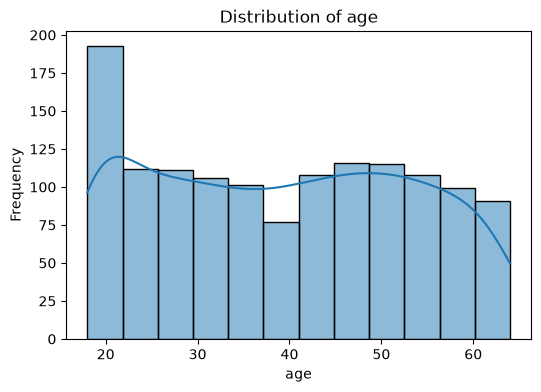

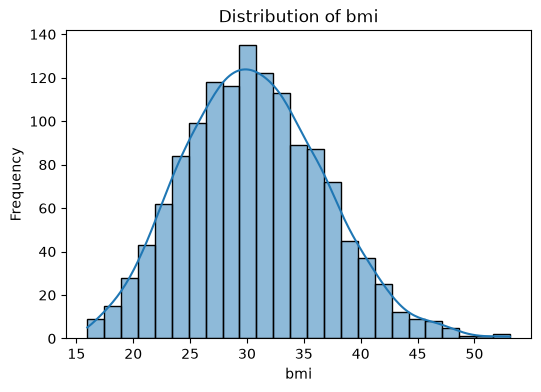

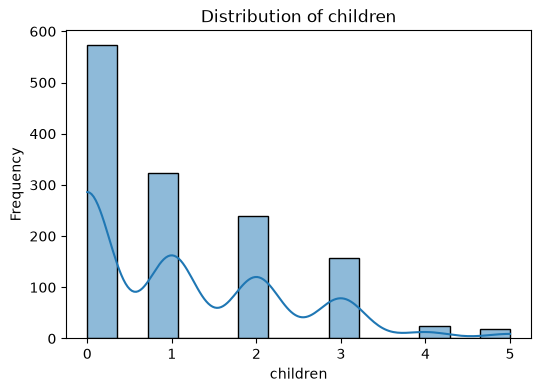

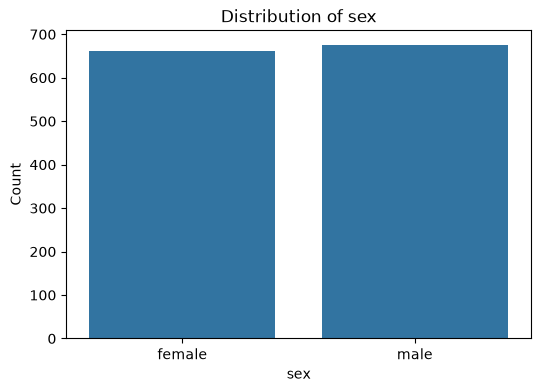

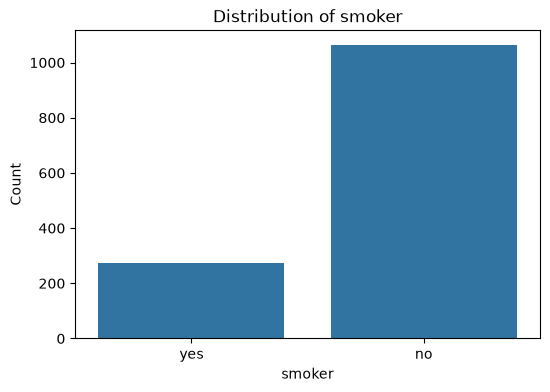

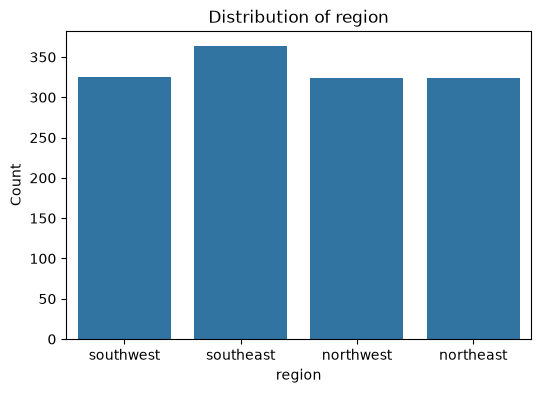

In [9]:
numeric_features = ['age', 'bmi', 'children']
categorical_features = ['sex', 'smoker', 'region']

# Numerical Features Distribution
for col in numeric_features:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

# Categorical Features Distribution
for col in categorical_features:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x=col)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

### 4.3 Correlation Analysis

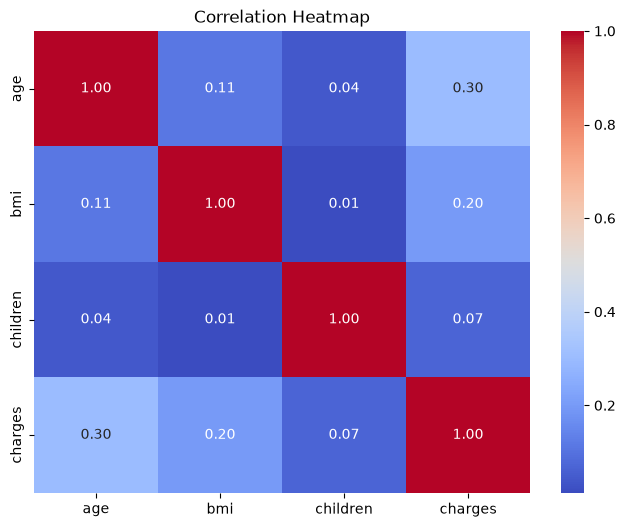

In [10]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

### 4.4 Bivariate Analysis

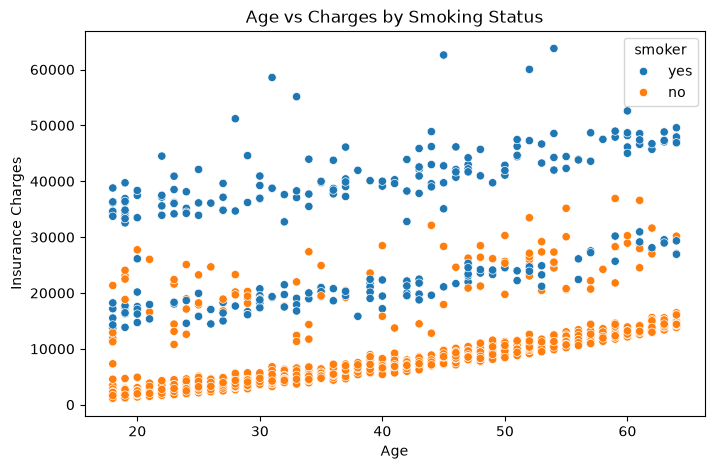

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='age',
    y='charges',
    hue='smoker'
)

plt.title('Age vs Charges by Smoking Status')
plt.xlabel('Age')
plt.ylabel('Insurance Charges')
plt.show()

# 5. Data Preprocessing

### 5.1 Separate Features and Target

In [12]:
X = df.drop('charges', axis=1)
y = df['charges']

### 5.2 Train / Validation / Test Split

In [13]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Testing Set:", X_test.shape)

Training Set: (935, 6)
Validation Set: (201, 6)
Testing Set: (201, 6)


### 5.3 Encoding and Scaling

In [14]:
numeric_features = ['age', 'bmi', 'children']
categorical_features = ['sex', 'smoker', 'region']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# 6. Model Training and Selection

### 6.1 Linear Regression (Scikit-learn)

In [15]:
lr = LinearRegression()

lr.fit(X_train_processed, y_train)
y_val_pred_lr = lr.predict(X_val_processed)

lr_val_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred_lr)
)

print("Linear Regression Validation RMSE:", lr_val_rmse)

Linear Regression Validation RMSE: 6316.681820232612


### 6.2 Linear Regression from Scratch

In [16]:
def LinearRegressionScratch(X_train, y_train, X_val):
    # Add bias column
    X_train_bias = np.c_[np.ones(X_train.shape[0]), X_train]
    X_val_bias = np.c_[np.ones(X_val.shape[0]), X_val]

    theta = np.linalg.pinv(X_train_bias) @ y_train

    predictions = X_val_bias @ theta

    return predictions


y_val_pred_scratch = LinearRegressionScratch(
    X_train_processed,
    y_train,
    X_val_processed
)

scratch_val_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred_scratch)
)

print("Scratch Linear Regression Validation RMSE:", scratch_val_rmse)

Scratch Linear Regression Validation RMSE: 6316.6818202326085


### 6.3 KNN Regressor — Hyperparameter Tuning

In [17]:
k_values = [3, 5, 7, 9, 11, 15, 20]

knn_results = {}

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)

    knn.fit(X_train_processed, y_train)

    y_val_pred = knn.predict(X_val_processed)

    rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

    knn_results[k] = rmse

    print(f"k = {k}, Validation RMSE = {rmse:.3f}")

k = 3, Validation RMSE = 6894.547
k = 5, Validation RMSE = 6857.457
k = 7, Validation RMSE = 7280.110
k = 9, Validation RMSE = 7447.939
k = 11, Validation RMSE = 7642.235
k = 15, Validation RMSE = 7817.659
k = 20, Validation RMSE = 8200.125


### 6.4 Select Best K

In [18]:
best_k = min(knn_results, key=knn_results.get)

print("Best K:", best_k)
print("Best Validation RMSE:", knn_results[best_k])

Best K: 5
Best Validation RMSE: 6857.457151552824


### 6.5 Train Final KNN Model

In [19]:
knn_final = KNeighborsRegressor(n_neighbors=best_k)

knn_final.fit(X_train_processed, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


### 6.6 Model Comparison

In [20]:
validation_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Scratch Linear Regression', 'KNN'],
    'Validation RMSE': [lr_val_rmse, scratch_val_rmse, knn_results[best_k]]
})

validation_results = validation_results.set_index('Model')

display(validation_results.round(3))

,Validation RMSE
Model,
Linear Regression,6316.682
Scratch Linear Regression,6316.682
KNN,6857.457


### 6.7 Select Best Model

In [21]:
best_model_name = validation_results['Validation RMSE'].idxmin()

print("Selected Model:", best_model_name)
print(
    "Best Validation RMSE:",
    validation_results.loc[best_model_name, 'Validation RMSE']
)

Selected Model: Scratch Linear Regression
Best Validation RMSE: 6316.6818202326085


# 7. Final Model Evaluation

### 7.1 Generate Test Predictions

In [22]:
y_test_pred_lr = lr.predict(X_test_processed)

y_test_pred_scratch = LinearRegressionScratch(
    X_train_processed,
    y_train,
    X_test_processed
)

y_test_pred_knn = knn_final.predict(X_test_processed)

### 7.2 Evaluate Models

In [23]:
test_predictions = {
    'Linear Regression': y_test_pred_lr,
    'Linear Regression from Scratch': y_test_pred_scratch,
    'KNN': y_test_pred_knn
}

rows = []

for name, pred in test_predictions.items():
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    })

metrics_df = pd.DataFrame(rows).set_index('Model')

display(metrics_df.round(3))

,MAE,RMSE,R2
Model,,,
Linear Regression,4041.915,6162.781,0.777
Linear Regression from Scratch,4041.915,6162.781,0.777
KNN,3627.134,6108.211,0.781


### 7.3 Actual vs Predicted Visualization

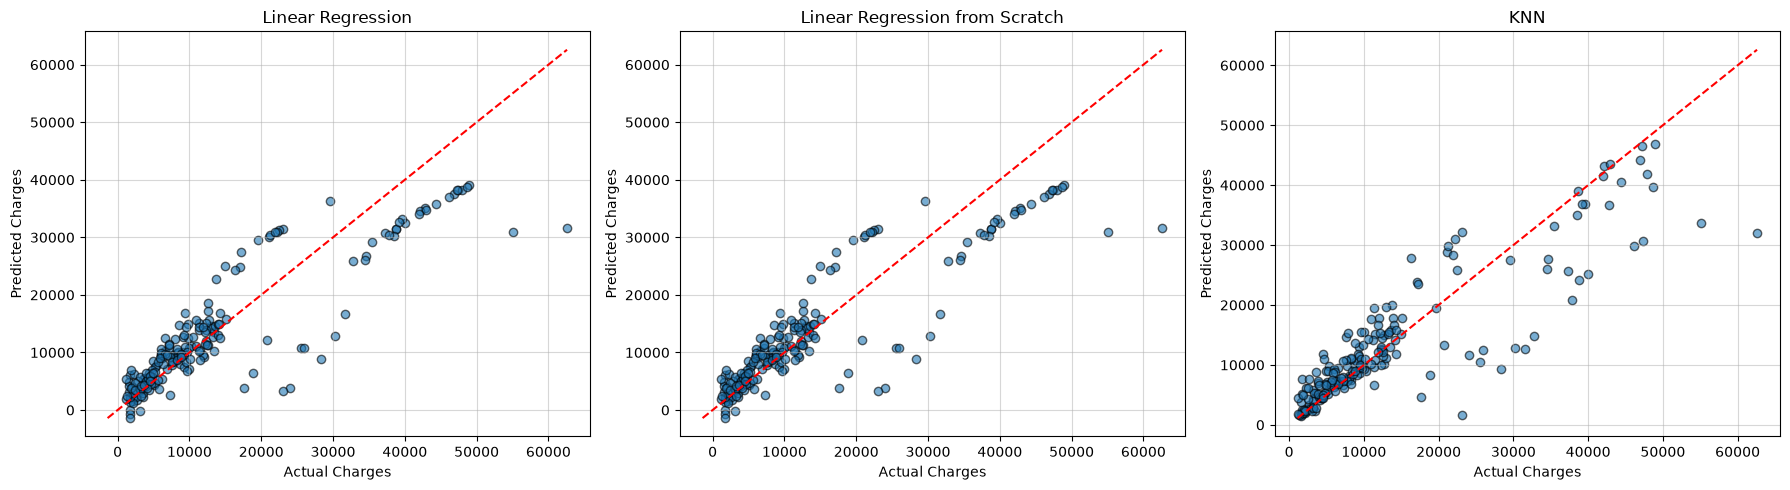

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, test_predictions.items()):
    ax.scatter(y_test, pred, alpha=0.6, edgecolor='k')

    lims = [
        min(y_test.min(), pred.min()),
        max(y_test.max(), pred.max())
    ]

    ax.plot(lims, lims, 'r--')

    ax.set_title(name)
    ax.set_xlabel('Actual Charges')
    ax.set_ylabel('Predicted Charges')
    ax.grid(alpha=0.5)

plt.tight_layout()
plt.show()

# 8. Model Persistence

### 8.1 Save the Final Model and Preprocessor

In [25]:
model_artifacts = {
    "preprocessor": preprocessor,
    "model": lr,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features
}

with open("insurance_model.pkl", "wb") as f:
    pickle.dump(model_artifacts, f)

print("Model saved to insurance_model.pkl")

Model saved to insurance_model.pkl


### 8.2 Load the Saved Model and Verify

In [26]:
with open("insurance_model.pkl", "rb") as f:
    loaded = pickle.load(f)

loaded_preprocessor = loaded["preprocessor"]
loaded_model = loaded["model"]

y_test_pred_loaded = loaded_model.predict(loaded_preprocessor.transform(X_test))

print("Predictions match:", np.allclose(y_test_pred_lr, y_test_pred_loaded))

Predictions match: True


### 8.3 Predict on a New Patient

In [27]:
new_patient = pd.DataFrame({
    "age": [35],
    "sex": ["male"],
    "bmi": [28.5],
    "children": [2],
    "smoker": ["no"],
    "region": ["southwest"]
})

prediction = loaded_model.predict(loaded_preprocessor.transform(new_patient))
print(f"Predicted insurance charges: ${prediction[0]:,.2f}")

Predicted insurance charges: $6,802.57


 ### 9 Ensemble Learning(using voting)




In [28]:
voting_model = VotingRegressor(
    estimators=[
        ('lr',LinearRegression()),
        ('knn', KNeighborsRegressor(n_neighbors=best_k))
    ]
)

### 9.2 Training the Voting Regressor

In [29]:
voting_model.fit(X_train_processed, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingRegressor`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('knn', ...)]"
,"weights weights: array-like of shape (n_regressors,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted values before averaging. Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
estimators_ estimators_: list of regressorsThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'.,list,"[LinearRegression(), KNeighborsRegressor()]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,11
named_estimators_ named_estimators_: :class:`~sklearn.utils.Bunch`Attribute to access any fitted sub-estimators by name... versionadded:: 0.20,Bunch,{'lr': Linear...rsRegressor()}
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06


### 9.3 Validation Prediction

In [30]:
y_val_pred_voting = voting_model.predict(X_val_processed)

y_val_pred_voting[:5]

array([12738.02937663,  4225.83007041, 13251.86793958,  4296.3726803 ,
        2777.92503283])

### 9.4  Evaluate Voting Regressor Using RMSE

In [31]:
voting_val_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred_voting)
)

print("Voting Validation RMSE:", voting_val_rmse)

Voting Validation RMSE: 6252.106352207961


### 9.5 Validation Models Comparison

In [32]:
validation_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'KNN', 'Voting Regressor'],
    'Validation RMSE': [lr_val_rmse,knn_results[best_k],voting_val_rmse]
})

display(validation_comparison.round(3))

,Model,Validation RMSE
0,Linear Regression,6316.682
1,KNN,6857.457
2,Voting Regressor,6252.106


The Voting Regressor achieved the lowest validation RMSE of 6252.106, showing a small improvement over Linear Regression and a larger improvement over KNN

### 9.6 Final Evaluation on the Test Set

In [33]:
y_test_pred_voting = voting_model.predict(X_test_processed)
voting_test_mae = mean_absolute_error(y_test,y_test_pred_voting )

print("Voting Test MAE:", voting_test_mae)

voting_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_voting)
)

print("Voting Test RMSE:", voting_test_rmse)

voting_test_r2 = r2_score(y_test, y_test_pred_voting)

print("Voting Test R2:", voting_test_r2)


Voting Test MAE: 3577.0729244189047
Voting Test RMSE: 5834.111417753136
Voting Test R2: 0.800554324993479


### 10 Final Comparison of Voting Regressor and Base Models

In [34]:
final_comparison = metrics_df.loc[
    ['Linear Regression', 'KNN'],
    ['MAE', 'RMSE', 'R2']
].copy()

final_comparison.loc['Voting Regressor'] = [
    voting_test_mae,
    voting_test_rmse,
    voting_test_r2
]

display(final_comparison.round(3))

,MAE,RMSE,R2
Model,,,
Linear Regression,4041.915,6162.781,0.777
KNN,3627.134,6108.211,0.781
Voting Regressor,3577.073,5834.111,0.801


### 11 Actual vs Predicted Values – Voting Regressor

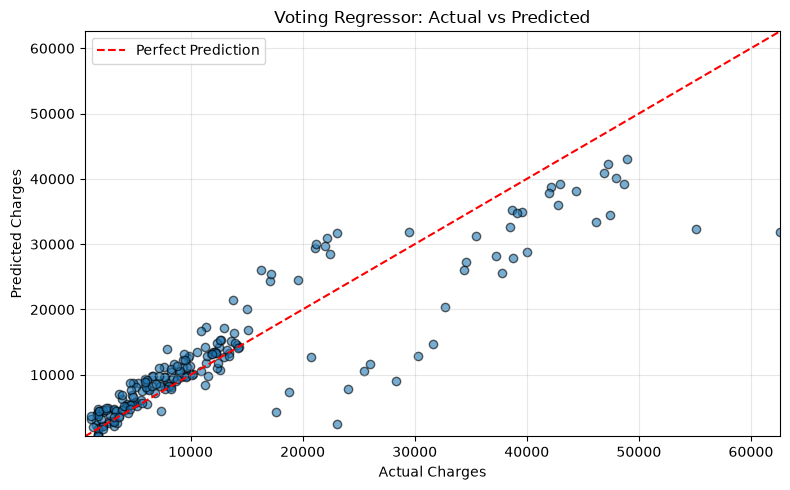

In [35]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_test_pred_voting, alpha=0.6, edgecolor='k')

lims = [
    min(y_test.min(), y_test_pred_voting.min()),
    max(y_test.max(), y_test_pred_voting.max())
]

plt.plot(lims, lims, 'r--', label='Perfect Prediction')

plt.xlim(lims)
plt.ylim(lims)

plt.title('Voting Regressor: Actual vs Predicted')
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

R² Score Comparison Using a Bar Chart
Objective: Compare the predictive performance of Linear Regression, KNN Regressor, and Voting Regressor using their R² scores on the same test dataset.

The R² scores are displayed as percentages for easier interpretation.

A higher R² score indicates that the model explains a greater proportion of the variance in medical insurance charges.

Note: R² percentages represent the coefficient of determination, not classification accuracy.

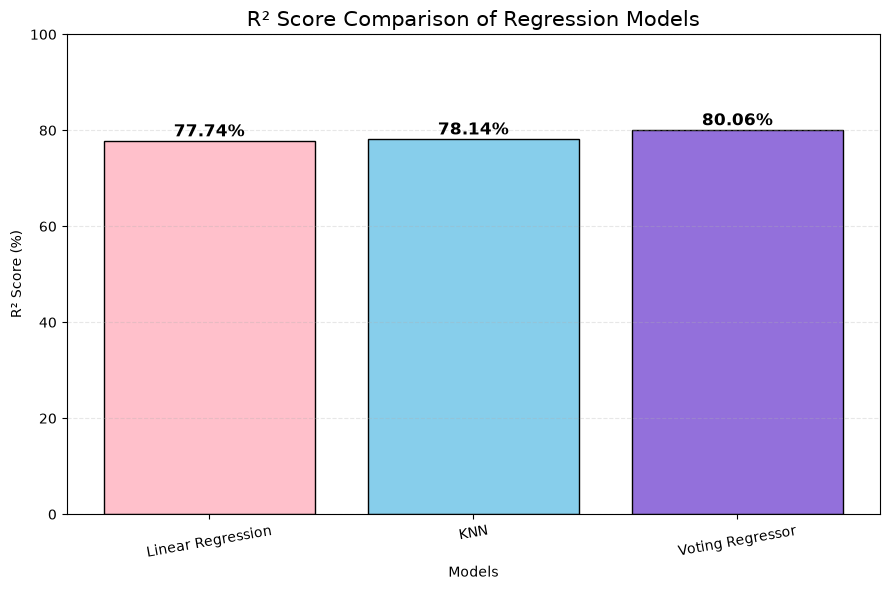

In [36]:
r2_scores = final_comparison["R2"] * 100

colors = ["pink", "skyblue", "mediumpurple"]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    r2_scores.index,
    r2_scores.values,
    color=colors,
    edgecolor="black"
)


for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.title("R² Score Comparison of Regression Models", fontsize=15)
plt.xlabel("Models")
plt.ylabel("R² Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=10)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
import sklearn
print(sklearn.__version__)

1.9.1
